In [1]:
from transformers import LongformerModel, LongformerTokenizer, LongformerConfig
import pandas as pd
import torch

In [3]:

# Load the CSV data, ensuring that both the row and column headers are properly read
data = pd.read_csv("/Users/nirwantandukar/input_data/Database.DREAM4/NORMALIZED_EXP/normalized_weight_matrix_all_GRN_100_01_0.1filter.csv", header=0, index_col=0)

# Parameters
num_genes = data.shape[0]  # Number of genes (rows)
num_columns_per_algorithm = 100  # Each algorithm has 100 columns
weight_threshold = 0.8  # Adjusted threshold for filtering tokens

# Reshape the data to separate each algorithm as a document
documents = []
for i in range(0, data.shape[1], num_columns_per_algorithm):
    algorithm_data = data.iloc[:, i:i+num_columns_per_algorithm].values
    documents.append(algorithm_data.flatten())  # Flatten the 100x100 matrix for each algorithm

# Tokenize gene pairs into strings like 'G1-G2' and combine with weights
tokens = [f'{gene1}-{gene2}' for gene1 in data.index for gene2 in data.columns[:num_genes]]

# Initialize the Longformer tokenizer and model
tokenizer = LongformerTokenizer.from_pretrained('allenai/longformer-base-4096')
model = LongformerModel.from_pretrained('allenai/longformer-base-4096')

# Preprocess the input for Longformer with filtering and correct padding
encoded_inputs = []
for document in documents:
    # Filter based on weight threshold
    filtered_input = [f"{tokens[idx]}: {value:.6f}" for idx, value in enumerate(document) if value >= weight_threshold]
    
    # If filtered input is non-empty, encode with padding and truncation
    if filtered_input:
        encoded_input = tokenizer(
            " ".join(filtered_input), 
            padding="max_length", 
            max_length=4096, 
            truncation=True, 
            return_tensors="pt"
        )
        # Ensure the attention mask and position ids are properly created
        encoded_input['attention_mask'] = torch.ones(encoded_input['input_ids'].shape, dtype=torch.long)
        encoded_inputs.append(encoded_input)

# Analyze using Longformer model with attention
def run_longformer_analysis_with_attention(encoded_input):
    with torch.no_grad():  # Disable gradients for inference
        output = model(**encoded_input, output_attentions=True)
        last_hidden_state = output.last_hidden_state
        attentions = output.attentions  # Extract attention scores
        return last_hidden_state, attentions

# Apply the Longformer model to each document and retrieve attention scores
longformer_outputs = []
attention_scores = []

for encoded_input in encoded_inputs:
    hidden_state, attentions = run_longformer_analysis_with_attention(encoded_input)
    longformer_outputs.append(hidden_state)
    attention_scores.append(attentions)  # Save attention scores

# Example: Inspect the attention scores for the first document (first GRN algorithm)
print("Attention scores shape:", attention_scores[0][0].shape)  # Print the shape of attention scores



/opt/anaconda3/envs/machine_learning/lib/python3.12/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


Attention scores shape: torch.Size([1, 12, 4096, 513])


In [7]:

# Set the attention threshold and hit count threshold
attention_threshold = 0.8
hit_count_threshold = 2

# Count how many times the attention score exceeds the threshold across heads and algorithms
# Assuming you have attention scores for each algorithm, sum over the heads dimension
hits_above_threshold = (averaged_attention > attention_threshold).sum(axis=0).astype(int)

# Ensure that the maximum hit count is capped at the number of algorithms (16 in your case)
hits_above_threshold = np.clip(hits_above_threshold, 0, 16)

# Identify the gene interactions that have at least `hit_count_threshold` hits above the threshold
significant_indices = np.where(hits_above_threshold >= hit_count_threshold)[0]

# Ensure filtered_input length matches the number of tokens (sequence length without padding)
filtered_input_length = len(filtered_input)

# Extract all significant interactions and corresponding hit counts
significant_interactions = [(filtered_input[idx], hits_above_threshold[idx]) 
                            for idx in significant_indices if idx < filtered_input_length]

# Create a DataFrame with the gene interactions and their hit counts
df_significant_interactions = pd.DataFrame(significant_interactions, columns=["Gene Interaction", "Hit Count"])

# Print the DataFrame of all significant interactions
print(df_significant_interactions)

# Save the DataFrame to a CSV if you want to keep a copy
df_significant_interactions.to_csv("significant_gene_interactions.csv", index=False)


NameError: name 'averaged_attention' is not defined

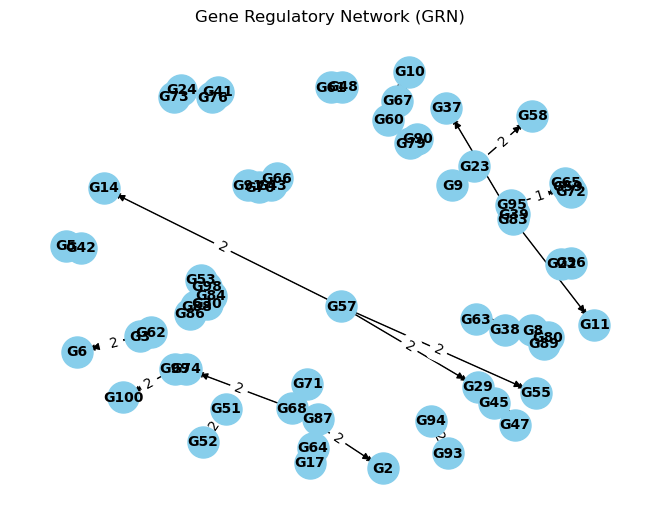

In [155]:
import networkx as nx
import matplotlib.pyplot as plt

# Assuming df_significant_interactions is already defined as per your output
# Example:
# df_significant_interactions = pd.DataFrame({
#    "Gene Interaction": ["G1-G4", "G5-G72", "G8-G63", ...],
#    "Hit Count": [[0, 0, 0, 0, 0], [0, 0, 0, 0, 0], ...]  # This should be actual hit counts.
# })

# Function to extract gene pairs and their hit counts
def extract_interactions(df):
    gene_interactions = []
    for i, row in df.iterrows():
        gene_pair = row['Gene Interaction'].split(':')[0]  # Split the gene interaction part
        hit_count = sum(row['Hit Count'])  # Sum of hits from the hit count list
        if hit_count > 0:
            gene_interactions.append((gene_pair, hit_count))
    return gene_interactions

# Create a Gene Regulatory Network (GRN) from the interactions
def create_grn_from_df(df):
    gene_interactions = extract_interactions(df)
    GRN = nx.DiGraph()  # Directed graph for regulatory interactions

    # Add edges to the graph with interaction counts as weights
    for interaction, count in gene_interactions:
        source_gene, target_gene = interaction.split('-')
        GRN.add_edge(source_gene, target_gene, weight=count)
    
    return GRN

# Visualize the GRN using NetworkX and Matplotlib
def visualize_grn(grn):
    pos = nx.spring_layout(grn)  # Layout for the graph
    edge_weights = nx.get_edge_attributes(grn, 'weight')

    # Draw the nodes
    nx.draw(grn, pos, with_labels=True, node_color='skyblue', node_size=500, font_size=10, font_weight='bold')
    
    # Draw the edges with varying thickness based on weight
    nx.draw_networkx_edges(grn, pos, width=[0.2 * w for w in edge_weights.values()])
    
    # Draw the edge labels (weights)
    nx.draw_networkx_edge_labels(grn, pos, edge_labels={k: f'{v}' for k, v in edge_weights.items()})

    plt.title("Gene Regulatory Network (GRN)")
    plt.show()

# Use the DataFrame you provided to create and visualize the GRN
grn = create_grn_from_df(df_significant_interactions)

# Visualize the GRN
visualize_grn(grn)


In [157]:
import pandas as pd

# Step 1: Load known (ground truth) interactions
#data = pd.read_csv("/Users/nirwantandukar/input_data/weights_normalized/normalize_weight_matrix_all_GRN_100_04.csv", header=0, index_col=0)
file_path = "/Users/nirwantandukar/input_data/Database.DREAM4/GS/dream4_100_05_gs.csv"  # Adjust to your file path
ground_truth = pd.read_csv(file_path, index_col=0)

# Convert ground truth matrix to edge list
def convert_matrix_to_edge_list(matrix):
    edges = []
    for source in matrix.index:
        for target in matrix.columns:
            if matrix.at[source, target] == 1:
                edges.append((source, target))
    return edges

# Get the ground truth edges
known_edges = convert_matrix_to_edge_list(ground_truth)

# Step 2: Get the predicted edges from the GRN
predicted_edges = list(grn.edges())

# Step 3: Compare the predicted and ground truth edges

# Convert edges to sets for easy comparison
known_edges_set = set(known_edges)
predicted_edges_set = set(predicted_edges)

# True Positives (correct predictions)
true_positives = predicted_edges_set.intersection(known_edges_set)

# False Positives (predicted edges that are not in the ground truth)
false_positives = predicted_edges_set.difference(known_edges_set)

# False Negatives (ground truth edges that are missing in the predictions)
false_negatives = known_edges_set.difference(predicted_edges_set)

# Step 4: Output the results
print(f"Number of True Positives (Correct edges): {len(true_positives)}")
print(f"Number of False Positives (Wrong edges): {len(false_positives)}")
print(f"Number of False Negatives (Missing edges): {len(false_negatives)}")

# Optional: print out the edges for further analysis
print(f"\nTrue Positive Edges:\n{true_positives}")
print(f"\nFalse Positive Edges:\n{false_positives}")
print(f"\nFalse Negative Edges:\n{false_negatives}")


Number of True Positives (Correct edges): 13
Number of False Positives (Wrong edges): 49
Number of False Negatives (Missing edges): 179

True Positive Edges:
{('G51', 'G52'), ('G8', 'G80'), ('G45', 'G47'), ('G38', 'G63'), ('G22', 'G36'), ('G29', 'G45'), ('G98', 'G53'), ('G64', 'G17'), ('G98', 'G84'), ('G72', 'G65'), ('G38', 'G89'), ('G83', 'G39'), ('G79', 'G90')}

False Positive Edges:
{('G91', 'G70'), ('G43', 'G70'), ('G53', 'G98'), ('G57', 'G55'), ('G23', 'G9'), ('G66', 'G43'), ('G71', 'G68'), ('G57', 'G29'), ('G83', 'G37'), ('G68', 'G71'), ('G62', 'G3'), ('G70', 'G43'), ('G30', 'G88'), ('G42', 'G5'), ('G3', 'G6'), ('G90', 'G79'), ('G60', 'G67'), ('G99', 'G74'), ('G76', 'G41'), ('G65', 'G72'), ('G89', 'G80'), ('G36', 'G22'), ('G84', 'G30'), ('G67', 'G60'), ('G86', 'G88'), ('G88', 'G30'), ('G84', 'G98'), ('G61', 'G48'), ('G68', 'G74'), ('G9', 'G23'), ('G30', 'G84'), ('G83', 'G11'), ('G95', 'G59'), ('G39', 'G83'), ('G23', 'G58'), ('G41', 'G76'), ('G67', 'G10'), ('G70', 'G91'), ('G57', 

In [13]:
#!pip install geneci
#import geneci
import pandas as pd
import numpy as np

!geneci run --expression-data /"Users/nirwantandukar/input_data/Database.DREAM4/EXP/dream4_100_05_exp.csv" \
            --technique ARACNE --technique BC3NET --technique C3NET --technique CLR \
           --technique GENIE3_RF --technique GRNBOOST2 --technique GENIE3_ET \
           --technique MRNET --technique MRNETB --technique PCIT --technique TIGRESS \
           --technique KBOOST --technique MEOMI --technique NARROMI --technique CMI2NI \
           --technique RSNET --technique PCACMI --technique LOCPCACMI --technique PLSNET \
           --technique PIDC --technique PUC --technique GRNVBEM --technique LEAP \
           --technique NONLINEARODES --technique INFERELATOR \
           --crossover-probability 0.9 --mutation-probability 0.05 --population-size 100 \
           --num-parents 3 --mutation-strength 0.1 \
           --num-evaluations 50000 --cut-off-criteria PercLinksWithBestConf --cut-off-value 0.4 \
           --function Quality --function DegreeDistribution --function Motifs \
           --algorithm NSGAII --plot-fitness-evolution --plot-pareto-front \
           --plot-parallel-coordinates --output-dir inferred_networks


                 __  ___  _  _  ___   __  __            
                / _)(  _)( \( )(  _) / _)(  )           
               ( (/\ ) _) )  (  ) _)( (_  )(            
                \__/(___)(_)\_)(___) \__)(__)           
                                                        
 version: 2.0.1     Author: Adrian Segura Ortiz <adrianseor.99@uma.es>        
                                                        

 Run algorithm for 
/Users/nirwantandukar/input_data/Database.DREAM4/EXP/dream4_100_05_exp.csv

 Total cores: 14
Distribution:
{
    <Technique.ARACNE: 'ARACNE'>: [0],
    <Technique.BC3NET: 'BC3NET'>: [1],
    <Technique.C3NET: 'C3NET'>: [0],
    <Technique.CLR: 'CLR'>: [1],
    <Technique.GENIE3_RF: 'GENIE3_RF'>: [3],
    <Technique.GRNBOOST2: 'GRNBOOST2'>: [4],
    <Technique.GENIE3_ET: 'GENIE3_ET'>: [5],
    <Technique.MRNET: 'MRNET'>: [0],
    <Technique.MRNETB: 'MRNETB'>: [1],
    <Technique.PCIT: 'PCIT'>: [0],
    <Technique.TIGRESS: 'TIGRESS'>: [6],
    <Technique

In [11]:
from transformers import LongformerModel, LongformerTokenizer
import pandas as pd
import torch
import numpy as np

# Load the CSV data, ensuring that both the row and column headers are properly read
#data = pd.read_csv("weights_NMF_all_GRN_05.csv", header=0, index_col=0)
data = pd.read_csv("/Users/nirwantandukar/input_data/weights_normalized/normalize_weight_matrix_all_GRN_100_04.csv", header=0, index_col=0)

# Parameters
num_genes = data.shape[0]  # Number of genes (rows)
num_columns_per_algorithm = 100  # Each algorithm has 100 columns
weight_threshold = 0.8  # Adjusted threshold for filtering tokens

# Reshape the data to separate each algorithm as a document
documents = []
for i in range(0, data.shape[1], num_columns_per_algorithm):
    algorithm_data = data.iloc[:, i:i+num_columns_per_algorithm].values
    documents.append(algorithm_data.flatten())  # Flatten the 100x100 matrix for each algorithm

# Tokenize gene pairs into strings like 'G1-G2' and combine with weights
tokens = [f'{gene1}-{gene2}' for gene1 in data.index for gene2 in data.columns[:num_genes]]

# Initialize the Longformer tokenizer and model
tokenizer = LongformerTokenizer.from_pretrained('allenai/longformer-base-4096')
model = LongformerModel.from_pretrained('allenai/longformer-base-4096')

# Preprocess the input for Longformer with filtering and correct padding
encoded_inputs = []
for document in documents:
    # Filter based on weight threshold
    filtered_input = [f"{tokens[idx]}: {value:.6f}" for idx, value in enumerate(document) if value >= weight_threshold]
    
    # If filtered input is non-empty, encode with padding and truncation
    if filtered_input:
        encoded_input = tokenizer(
            " ".join(filtered_input), 
            padding="max_length", 
            max_length=4096, 
            truncation=True, 
            return_tensors="pt"
        )
        # Ensure the attention mask and position ids are properly created
        encoded_input['attention_mask'] = torch.ones(encoded_input['input_ids'].shape, dtype=torch.long)
        encoded_inputs.append(encoded_input)

# Analyze using Longformer model with attention
def run_longformer_analysis_with_attention(encoded_input):
    with torch.no_grad():  # Disable gradients for inference
        output = model(**encoded_input, output_attentions=True)
        last_hidden_state = output.last_hidden_state
        attentions = output.attentions  # Extract attention scores
        return last_hidden_state, attentions

# Apply the Longformer model to each document and retrieve attention scores
longformer_outputs = []
attention_scores = []

for encoded_input in encoded_inputs:
    hidden_state, attentions = run_longformer_analysis_with_attention(encoded_input)
    longformer_outputs.append(hidden_state)
    attention_scores.append(attentions)  # Save attention scores

# Now that we have the attention scores, we need to average them across layers and heads
# Attention scores have the shape: (batch_size, num_heads, sequence_length, sequence_length)
# You can average across heads and layers (depending on your preference)

# Example: Average attention across heads and layers for each algorithm
averaged_attention_scores = [torch.mean(torch.stack(attn), dim=0).squeeze(0).numpy() for attn in attention_scores]

# Set the attention threshold and hit count threshold
attention_threshold = 0.6
hit_count_threshold = 1

# Now count the number of hits above the threshold across heads and layers
hits_above_threshold = []
for avg_attention in averaged_attention_scores:
    hits = (avg_attention > attention_threshold).sum(axis=0).astype(int)  # Sum over the heads/layers
    hits_above_threshold.append(hits)

# Aggregate the hits across all algorithms/documents
hits_above_threshold = np.sum(hits_above_threshold, axis=0)

# Ensure that the maximum hit count is capped at the number of algorithms (16 in your case)
hits_above_threshold = np.clip(hits_above_threshold, 0, len(documents))

# Identify the gene interactions that have at least `hit_count_threshold` hits above the threshold
significant_indices = np.where(hits_above_threshold >= hit_count_threshold)[0]

# Ensure filtered_input length matches the number of tokens (sequence length without padding)
filtered_input_length = len(filtered_input)

# Extract all significant interactions and corresponding hit counts
significant_interactions = [(tokens[idx], hits_above_threshold[idx]) 
                            for idx in significant_indices if idx < filtered_input_length]

# Create a DataFrame with the gene interactions and their hit counts
df_significant_interactions = pd.DataFrame(significant_interactions, columns=["Gene Interaction", "Hit Count"])

# Print the DataFrame of all significant interactions
print(df_significant_interactions)

# Save the DataFrame to a CSV if you want to keep a copy
df_significant_interactions.to_csv("significant_gene_interactions.csv", index=False)


/opt/anaconda3/envs/machine_learning/lib/python3.12/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


    Gene Interaction                                          Hit Count
0   G1-GRN_ARACNE.G1  [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...
1  G1-GRN_ARACNE.G10  [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...


In [13]:
print(df_significant_interactions)

    Gene Interaction                                          Hit Count
0   G1-GRN_ARACNE.G1  [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...
1  G1-GRN_ARACNE.G10  [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...
